# Sovereign Credit Outlooks with an Open LLM: Macro Fact Sheets, Newspaper Headlines and Machine Learning, Tested Against Subsequent Bond Spreads

Rating agencies attach an outlook to every sovereign rating, mixing hard numbers with judgement about politics and events. Can an open language model, given the same kind of fact sheet and the year's headlines, form an outlook that tells you anything about where bond spreads go next? This notebook tests that against what actually happened.

**What it does.** It asks an open-weight language model (Qwen2.5-1.5B-Instruct, run locally) to act as a sovereign analyst. For each of 32 countries and each year since 2017, the model reads a short fact sheet and gives a 12-month credit outlook (positive, stable or negative, as rating agencies phrase it). The fact sheet contains:

- the country's debt, deficit, growth, inflation, current account and reserves;
- its 10-year yield spread;
- ten news headlines about its economy that year, from The Guardian and The New York Times.

The outlooks are scored against what happened next: the change in the country's 10-year government bond spread over the following year. They are compared with machine-learning models trained on the same numbers, and the model writes outlook notes for the latest year.

**Data.** FRED (OECD 10-year government bond yields), the IMF World Economic Outlook through the DataMapper API (general government debt and net lending, with FRED and the World Bank as fallbacks), the World Bank WDI API (growth, inflation, current account, reserves), and The Guardian Open Platform and New York Times Archive APIs (headlines).

**Methods.** Prompt-based zero-shot classification from next-token probabilities, walk-forward logistic regression and LightGBM, AUC and rank correlation against realised spread changes, and greedy text generation for outlook notes.

**Key output.** How well LLM outlooks rank countries by subsequent spread widening, compared with ML and simple rules, and outlook notes for today.

## 1. Rating outlooks and what they predict

Agencies attach an **outlook** to each sovereign rating: positive, stable or negative over 12–24 months. It rests on a mix of:
- **quantitative factors:** debt, fiscal balance, growth, external position, inflation;
- **qualitative judgement:** politics, institutions, events.

Historical agency outlooks and ratings are proprietary, so this notebook uses a market outcome instead: the **change in the 10-year government bond spread** over the next 12 months. The spread is measured over Germany for euro-area members and over the United States for the others. A deteriorating outlook should precede widening spreads.

For non-euro countries the spread mixes credit risk with expected inflation and currency risk, so the target is a sovereign *risk premium* rather than pure credit risk. Euro-area spreads over the Bund are the cleanest credit measure, and they are reported separately.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import json
import torch
import transformers
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 83
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
LLM = "Qwen/Qwen2.5-1.5B-Instruct"
# headlines collected up to this date (fixed, so the cached downloads stay
# valid)
NEWS_AS_OF = pd.Timestamp("2026-10-20")
COUNTRIES = {
    "AU": "Australia",
    "AT": "Austria",
    "BE": "Belgium",
    "CA": "Canada",
    "CL": "Chile",
    "CO": "Colombia",
    "CZ": "Czech Republic",
    "DK": "Denmark",
    "FI": "Finland",
    "FR": "France",
    "GR": "Greece",
    "HU": "Hungary",
    "IS": "Iceland",
    "IE": "Ireland",
    "IL": "Israel",
    "IT": "Italy",
    "JP": "Japan",
    "KR": "South Korea",
    "MX": "Mexico",
    "NL": "Netherlands",
    "NZ": "New Zealand",
    "NO": "Norway",
    "PL": "Poland",
    "PT": "Portugal",
    "SK": "Slovakia",
    "SI": "Slovenia",
    "ZA": "South Africa",
    "ES": "Spain",
    "SE": "Sweden",
    "CH": "Switzerland",
    "GB": "United Kingdom",
    "DE": "Germany",
}
EURO = {
    "AT",
    "BE",
    "FI",
    "FR",
    "GR",
    "IE",
    "IT",
    "NL",
    "PT",
    "SK",
    "SI",
    "ES",
    "DE",
}
# outlook dates: end of each year
YEARS = range(2017, dt.date.today().year)
# "deteriorated": the spread widened by more than 25 bp over the next 12 months
WIDEN_BP = 25

print(
    f"transformers {transformers.__version__} · torch {torch.__version__} ·"
    f" lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

…/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


transformers 5.20.1 · torch 2.14.1+cu130 · lightgbm 4.7.0 · run on 2026-10-22


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


# --- News sources: NYT Archive API, The Guardian Open Platform, FNSPID
# (Hugging Face), SEC 8-K filings
# Free keys go in .env:  NYT_API_KEY (developer.nytimes.com, Archive API)  ·
# GUARDIAN_API_KEY (open-platform.theguardian.com)
import csv
import gzip
import json
import sys

NYT_KEY, GUARDIAN_KEY = (
    os.getenv("NYT_API_KEY", "").strip(),
    os.getenv("GUARDIAN_API_KEY", "").strip(),
)
NYT_DIR = DATA_DIR / "nyt_archive"
NYT_DIR.mkdir(exist_ok=True)
_NYT_KEEP = [
    "pub_date",
    "section_name",
    "news_desk",
    "type_of_material",
    "document_type",
    "word_count",
    "web_url",
]


def nyt_month(m):
    """
    Every article the New York Times published in month m (metadata only),
    cached as gzip JSON in data/nyt_archive/.
    """
    path = NYT_DIR / f"{m}.json.gz"
    if path.exists():
        return pd.DataFrame(json.load(gzip.open(path, "rt")))
    if not NYT_KEY:
        raise RuntimeError(
            "NYT_API_KEY not found in .env (free key at developer.nytimes.com,"
            " Archive API)."
        )
    for k in range(6):
        r = requests.get(
            f"https://api.nytimes.com/svc/archive/v1/{m.year}/{m.month}.json",
            params={"api-key": NYT_KEY},
            timeout=180,
        )
        if r.status_code == 200:
            rows = [
                {
                    **{c: d.get(c) for c in _NYT_KEEP},
                    "headline": (d.get("headline") or {}).get("main"),
                    "abstract": d.get("abstract"),
                    "lead": d.get("lead_paragraph"),
                    "keywords": "; ".join(
                        f"{x.get('name')}:{x.get('value')}"
                        for x in (d.get("keywords") or [])
                    ),
                }
                for d in r.json()["response"]["docs"]
            ]
            with gzip.open(path, "wt") as fh:
                json.dump(rows, fh)
            # the Archive API allows about five requests a minute
            time.sleep(13)
            return pd.DataFrame(rows)
        time.sleep(60 * (k + 1))
    raise RuntimeError(f"NYT Archive API not answering for {m}")


def nyt_archive(start, end):
    months = pd.period_range(start, end, freq="M")
    A = pd.concat(
        [nyt_month(m).assign(month=str(m)) for m in months], ignore_index=True
    )
    A["date"] = pd.to_datetime(A["pub_date"], utc=True, errors="coerce")
    return A


def guardian_search(params):
    """
    One Guardian Content API request (12 per second and 5,000 a day are allowed
    on the free tier; this client is slower).
    """
    if not GUARDIAN_KEY:
        raise RuntimeError(
            "GUARDIAN_API_KEY not found in .env (free key at"
            " open-platform.theguardian.com)."
        )
    for k in range(6):
        try:
            r = requests.get(
                "https://content.guardianapis.com/search",
                params={**params, "api-key": GUARDIAN_KEY},
                timeout=60,
            )
            if r.status_code == 200:
                time.sleep(1.1)
                return r.json()["response"]
            time.sleep(30 * (k + 1))
        except requests.RequestException:
            time.sleep(30)
    return {"results": [], "pages": 0}


def guardian_rows(resp, **extra):
    return [
        {
            "date": x.get("webPublicationDate"),
            "title": x.get("webTitle"),
            "section": x.get("sectionName"),
            "trail": (x.get("fields") or {}).get("trailText"),
            **extra,
        }
        for x in resp.get("results", [])
    ]


def guardian_companies(queries, start, end):
    """
    Every Guardian business, technology or money article that names the company
    together with a markets word.
    """
    out = []
    for tk, q in queries.items():
        base = {
            "q": (
                f"{q} AND (shares OR stock OR earnings OR investors OR profit"
                " OR revenue)"
            ),
            "section": "business|technology|money",
            "from-date": start,
            "to-date": end,
            "page-size": 200,
            "show-fields": "trailText",
            "order-by": "oldest",
        }
        first = guardian_search({**base, "page": 1})
        out += guardian_rows(first, ticker=tk)
        for pg in range(2, int(first.get("pages", 0)) + 1):
            out += guardian_rows(
                guardian_search({**base, "page": pg}), ticker=tk
            )
    return pd.DataFrame(out)


FNSPID_URL = "https://huggingface.co/datasets/sabareesh88/FNSPID_nasdaq/resolve/main/data/train-{:05d}-of-00048.parquet"


def fnspid_headlines(tickers):
    """
    FNSPID (Dong, Fan and Chen, 2024), Nasdaq.com news file on Hugging Face (48
    Parquet shards, 10.6 GB): reads over HTTP only the
    row groups whose symbol range contains one of the tickers, and only four
    columns, so a few hundred MB are transferred.
    """
    import fsspec
    import pyarrow.parquet as pq

    T, fs, keep = (
        set(tickers),
        fsspec.filesystem("https", client_kwargs={"trust_env": True}),
        [],
    )
    for i in range(48):
        f = pq.ParquetFile(fs.open(FNSPID_URL.format(i), block_size=2**22))
        j = f.schema_arrow.names.index("Stock_symbol")
        for g in range(f.metadata.num_row_groups):
            st = f.metadata.row_group(g).column(j).statistics
            if (
                st is None
                or not st.has_min_max
                or any(st.min <= t <= st.max for t in T)
            ):
                d = f.read_row_group(
                    g,
                    columns=[
                        "Date",
                        "Article_title",
                        "Stock_symbol",
                        "Publisher",
                    ],
                ).to_pandas()
                keep.append(
                    d[d["Stock_symbol"].astype(str).str.upper().isin(T)]
                )
    return pd.concat(keep, ignore_index=True).drop_duplicates(
        ["Date", "Article_title", "Stock_symbol"]
    )


ITEMS_8K = {
    "1.01": "entry into a material agreement",
    "1.02": "termination of a material agreement",
    "1.03": "bankruptcy or receivership",
    "2.01": "completion of an acquisition or disposition",
    "2.02": "results of operations and financial condition",
    "2.03": "new direct financial obligation",
    "2.05": "exit or restructuring costs",
    "2.06": "material impairment",
    "3.01": "delisting notice",
    "3.03": "change to the rights of security holders",
    "4.01": "change of auditor",
    "4.02": "non-reliance on previous financial statements",
    "5.02": "departure or appointment of directors or officers",
    "5.03": "amendment to articles or bylaws",
    "5.07": "shareholder vote results",
    "7.01": "Regulation FD disclosure",
    "8.01": "other material events",
    "9.01": "financial statements and exhibits",
}
# Exxon Mobil Corp filed under this CIK until its 2026 holding-company
# reorganisation
SEC_EXTRA_CIK = {"XOM": ["0000034088"]}


def sec_8k(tickers, start):
    """
    Every 8-K a company filed since `start`: acceptance time, item codes, and
    the headline and opening text of its press release (EX-99).
    """
    import html as _html

    H = {
        "User-Agent": os.getenv(
            "SEC_USER_AGENT", "research contact@example.com"
        )
    }

    def get(url, js=True):
        for k in range(6):
            time.sleep(0.13)
            try:
                r = requests.get(url, headers=H, timeout=60)
                if r.status_code == 200:
                    return r.json() if js else r.text
                if r.status_code == 404:
                    return None
            except requests.RequestException:
                pass
            time.sleep(5 * (k + 1))
        return None

    skip = re.compile(
        r"exhibit|press release|for immediate release|news"
        r" release|contact|investor relations|media relations|^page"
        r" \d|^\(?\d|^[\W_]*$|^[A-Z][a-z]+ \d{1,2}, \d{4}$|^\w+, \w+ \d",
        re.I,
    )

    def head_text(raw):
        raw = re.sub(r"(?is)<(script|style).*?</\1>", " ", raw)
        raw = re.sub(r"(?i)<br\s*/?>|</(p|div|tr|h\d|li)>", "\n", raw)
        lines = [
            re.sub(r"\s+", " ", x).strip()
            for x in _html.unescape(re.sub(r"<[^>]+>", " ", raw))
            .replace("\xa0", " ")
            .split("\n")
        ]
        lines = [x for x in lines if x]
        return (
            next(
                (
                    x
                    for x in lines[:40]
                    if not skip.search(x) and 4 <= len(x.split()) <= 30
                ),
                None,
            ),
            " ".join(lines)[:3000],
        )

    cik = {
        v["ticker"]: str(v["cik_str"]).zfill(10)
        for v in get("https://www.sec.gov/files/company_tickers.json").values()
    }
    out = []
    for tk, c in [(t, cik[t]) for t in tickers] + [
        (t, x) for t, xs in SEC_EXTRA_CIK.items() if t in tickers for x in xs
    ]:
        sub = get(f"https://data.sec.gov/submissions/CIK{c}.json")
        F = pd.concat(
            [pd.DataFrame(sub["filings"]["recent"])]
            + [
                pd.DataFrame(
                    get(f"https://data.sec.gov/submissions/{f['name']}")
                )
                for f in sub["filings"].get("files", [])
            ]
        )
        for _, r in F[
            F["form"].isin(["8-K", "8-K/A"]) & (F["filingDate"] >= start)
        ].iterrows():
            base = (
                f"https://www.sec.gov/Archives/edgar/data/{int(c)}/{r['accessionNumber'].replace('-', '')}"
            )
            names = [
                x["name"]
                for x in (
                    (get(f"{base}/index.json") or {})
                    .get("directory", {})
                    .get("item", [])
                )
            ]
            ex = sorted(
                [
                    x
                    for x in names
                    if re.search(r"ex-?99|dex99", x, re.I)
                    and x.lower().endswith((".htm", ".html", ".txt"))
                ],
                key=lambda x: (
                    0 if re.search(r"99[-_.]?0?1|991", x) else 1,
                    x,
                ),
            )
            raw = get(f"{base}/{ex[0]}", js=False) if ex else None
            h, t = head_text(raw) if raw else (None, None)
            out.append({
                "acc": r["accessionNumber"],
                "ticker": tk,
                "form": r["form"],
                "filed": r["filingDate"],
                "accepted": r["acceptanceDateTime"],
                "items": r.get("items", ""),
                "exhibit": ex[0] if ex else None,
                "headline": h,
                "text": t,
            })
    return pd.DataFrame(out)


def sec_8k_titles(K, names):
    """
    One headline per 8-K: the press-release headline when it reads like one,
    otherwise '<Company> 8-K: <item descriptions>'.
    """
    good = K["headline"].fillna("").str.len().between(25, 250) & ~K[
        "headline"
    ].fillna("").str.contains(
        r"\d{5}|financial supplement|for release|^(?:the )?[\w.&,\- ]+"
        r" (?:inc|corp|corporation|company|co)\.?$",
        regex=True,
        case=False,
    )
    desc = (
        K["items"]
        .fillna("")
        .map(
            lambda s: "; ".join(
                ITEMS_8K[x]
                for x in s.split(",")
                if x in ITEMS_8K and x != "9.01"
            )
        )
    )
    title = np.where(
        good, K["headline"], K["ticker"].map(names) + " 8-K: " + desc
    )
    # The submissions API labels acceptance times "Z" but they run ahead of
    # true UTC by the New York UTC offset (checked against the filing
    # index pages: 16:30 New York time appears as 00:30Z in summer and 02:30Z
    # in winter). Two conversions recover the New York time.
    t = (
        pd.to_datetime(K["accepted"], utc=True, errors="coerce")
        .dt.tz_convert("America/New_York")
        .dt.tz_localize(None)
    )
    t = t.dt.tz_localize("UTC").dt.tz_convert("America/New_York")
    return K.assign(title=title, date=t.astype(str))[
        ["ticker", "date", "title", "items"]
    ]


# Compact finance word lists in the spirit of Loughran and McDonald (2011): a
# dictionary benchmark for the language models
POS_WORDS = r"\b(beat|beats|gain|gains|gained|surge|surges|surged|soar|soared|record|strong|stronger|growth|grow|grows|profit|profits|upgrade|upgraded|rally|rallies|rallied|rise|rises|rose|boost|boosted|outperform\w*|exceed\w*|improv\w*|win|wins|approval|approved)\b"
NEG_WORDS = r"\b(miss|misses|missed|loss|losses|lose|loses|lost|fall|falls|fell|drop|drops|dropped|plunge\w*|slump\w*|weak|weaker|cut|cuts|downgrade\w*|lawsuit\w*|probe|fine|fined|recall\w*|decline\w*|warn\w*|layoff\w*|risk|risks|crash\w*|fraud|default\w*|bankrupt\w*)\b"


def wordlist_tone(texts):
    t = pd.Series(texts).fillna("")
    pos, neg = t.str.count(POS_WORDS, flags=re.I), t.str.count(
        NEG_WORDS, flags=re.I
    )
    return ((pos - neg) / (pos + neg).replace(0, np.nan)).fillna(0).values

## 3. The fact-sheet data

- **10-year yields:** OECD long-term interest rates on FRED (`IRLTLT01{country}M156N`), monthly. The spread at year-end and its change over the next 12 months give the target.
- **Fiscal:** IMF general government gross debt and net lending (% of GDP) on FRED (`GGGDTA…`, `GGNLBA…`).
- **Macro:** World Bank WDI API: real GDP growth, CPI inflation, current-account balance (% of GDP) and total reserves in months of imports.

For an outlook at the end of year Y, the macro values are those for year Y − 1, the latest published when the outlook is made.

In [3]:
def fred_or_nan(sid):
    try:
        s = fred.get_series(sid).dropna()
        s.index = pd.to_datetime(s.index)
        return s
    except Exception:
        return pd.Series(dtype=float)


def fetch_yields():
    return pd.DataFrame(
        {c: fred_or_nan(f"IRLTLT01{c}M156N") for c in list(COUNTRIES) + ["US"]}
    ).reset_index(names="date")


ISO3 = {
    "AU": "AUS",
    "AT": "AUT",
    "BE": "BEL",
    "CA": "CAN",
    "CL": "CHL",
    "CO": "COL",
    "CZ": "CZE",
    "DK": "DNK",
    "FI": "FIN",
    "FR": "FRA",
    "GR": "GRC",
    "HU": "HUN",
    "IS": "ISL",
    "IE": "IRL",
    "IL": "ISR",
    "IT": "ITA",
    "JP": "JPN",
    "KR": "KOR",
    "MX": "MEX",
    "NL": "NLD",
    "NZ": "NZL",
    "NO": "NOR",
    "PL": "POL",
    "PT": "PRT",
    "SK": "SVK",
    "SI": "SVN",
    "ZA": "ZAF",
    "ES": "ESP",
    "SE": "SWE",
    "CH": "CHE",
    "GB": "GBR",
    "DE": "DEU",
}


def fetch_fiscal():
    """
    General government debt and net lending (% of GDP), from three sources in
    order of preference:
    the IMF World Economic Outlook (DataMapper API), FRED's copy of the IMF
    series, and the World Bank (central government).
    """
    rows = []
    # 1. IMF WEO, all countries
    for k, ind in [("debt", "GGXWDG_NGDP"), ("net_lending", "GGXCNL_NGDP")]:
        try:
            # all countries (a long country list in the URL returns 404)
            j = requests.get(
                f"https://www.imf.org/external/datamapper/api/v1/{ind}",
                timeout=120,
            ).json()["values"][ind]
            back = {v: c for c, v in ISO3.items()}
            rows += [
                {"iso2": back[i3], "year": int(y), k: v, "src": "IMF WEO"}
                for i3, d in j.items()
                if i3 in back
                for y, v in d.items()
                if v is not None
            ]
        except Exception as err:
            print(
                f"IMF DataMapper not reachable ({type(err).__name__}); using"
                " FRED and the World Bank"
            )
    # 2. FRED (IMF series for a subset of countries)
    for c in COUNTRIES:
        for k, sid in [
            ("debt", f"GGGDTA{c}A188N"),
            ("net_lending", f"GGNLBA{c}A188N"),
        ]:
            rows += [
                {"iso2": c, "year": d.year, k: v, "src": "FRED"}
                for d, v in fred_or_nan(sid).items()
            ]
    # 3. World Bank, central government
    for k, ind in [
        ("debt", "GC.DOD.TOTL.GD.ZS"),
        ("net_lending", "GC.NLD.TOTL.GD.ZS"),
    ]:
        j = requests.get(
            f"https://api.worldbank.org/v2/country/{';'.join(COUNTRIES)}/indicator/{ind}?format=json&per_page=5000&date=2005:{dt.date.today().year}",
            timeout=60,
        ).json()
        rows += [
            {
                "iso2": r["country"]["id"],
                "year": int(r["date"]),
                k: r["value"],
                "src": "World Bank",
            }
            for r in j[1]
            if r["value"] is not None
        ]
    R = pd.DataFrame(rows)
    R["rank"] = R["src"].map({"IMF WEO": 0, "FRED": 1, "World Bank": 2})
    R = R.sort_values("rank")
    out = (
        R.groupby(["iso2", "year"])[["debt", "net_lending"]]
        .first()
        .reset_index()
    )
    # past years only (the WEO also publishes projections)
    return out[out["year"] < dt.date.today().year]


WB = {
    "growth": "NY.GDP.MKTP.KD.ZG",
    "inflation": "FP.CPI.TOTL.ZG",
    "current_account": "BN.CAB.XOKA.GD.ZS",
    "reserves_months": "FI.RES.TOTL.MO",
}


def fetch_wdi():
    out = []
    for k, ind in WB.items():
        url = f"https://api.worldbank.org/v2/country/{';'.join(COUNTRIES)}/indicator/{ind}?format=json&per_page=5000&date=2010:{dt.date.today().year}"
        j = requests.get(url, timeout=60).json()
        out += [
            {"iso2": r["country"]["id"], "year": int(r["date"]), k: r["value"]}
            for r in j[1]
            if r["value"] is not None
        ]
    return pd.DataFrame(out).groupby(["iso2", "year"]).first().reset_index()


YLD = cached("yields", fetch_yields, max_age_hours=24 * 7).set_index("date")
FIS = cached("fiscal_v2", fetch_fiscal, max_age_hours=24 * 30).sort_values(
    ["iso2", "year"]
)
WDI = cached("wdi", fetch_wdi, max_age_hours=24 * 30)
ye = YLD.resample("YE").last()
spread = pd.DataFrame({
    c: (ye[c] - (ye["DE"] if c in EURO and c != "DE" else ye["US"])) * 100
    for c in COUNTRIES
    if c in ye and c != "DE"
})
print(
    f"Yields for {YLD.notna().any().sum()} series · fiscal rows {len(FIS)} ·"
    f" WDI rows {len(WDI)} · last yield month"
    f" {YLD.dropna(how='all').index.max():%Y-%m}"
)
spread.iloc[-6:].round(0)

Yields for 32 series · fiscal rows 1261 · WDI rows 512 · last yield month 2026-09


,AU,AT,BE,CA,CL,CO,CZ,DK,FI,FR,...,NO,PL,PT,SK,SI,ZA,ES,SE,CH,GB
date,,,,,,,,,,,,,,,,,,,,,
2021-12-31,14.00,34.00,41.00,-2.00,422.00,NaN,115.00,-155.00,32.00,43.00,...,24.00,186.00,74.00,36.00,55.00,843.00,80.00,-133.00,-160.00,-63.00
2022-12-31,-7.00,65.00,61.00,-68.00,172.00,NaN,109.00,-134.00,32.00,53.00,...,-48.00,299.00,101.00,111.00,143.00,776.00,103.00,-165.00,-206.00,-12.00
2023-12-31,17.00,58.00,60.00,-79.00,146.00,NaN,-5.00,-166.00,58.00,55.00,...,-78.00,119.00,75.00,121.00,116.00,747.00,104.00,-181.00,-336.00,-16.00
2024-12-31,-8.00,44.00,62.00,-123.00,137.00,NaN,-26.00,-248.00,47.00,84.00,...,-73.00,134.00,50.00,104.00,71.00,586.00,71.00,-229.00,-407.00,4.00
2025-12-31,58.00,28.00,51.00,-75.00,122.00,NaN,51.00,-143.00,35.00,74.00,...,-5.00,107.00,33.00,65.00,44.00,465.00,46.00,-132.00,-381.00,34.00
2026-12-31,29.00,-6.00,29.00,-111.00,102.00,NaN,-8.00,-198.00,33.00,101.00,...,-58.00,124.00,38.00,38.00,7.00,396.00,45.00,-180.00,-440.00,25.00


## 4. Headlines per country and year

For each country and year, two newspaper archives are searched:
- **The Guardian** (Open Platform API): the 50 most relevant business, world or politics articles matching `"<country>" AND (economy OR budget OR debt OR deficit OR bonds OR "credit rating")`;
- **The New York Times** (Archive API, every article of every month): business and world articles whose headline or abstract names the country together with one of the same economic words.

Search results also include articles that only mention a country in passing (a UK budget story that cites Italy), so an article is kept only if its headline or standfirst names the country or uses its adjective. This removes about three quarters of the Guardian results and leaves a median of about ten articles per country and year.

All headlines published during year Y are used for the outlook at the end of Y, so none is from the future. The ten most relevant ones (Guardian relevance order, then NYT) go into the fact sheet. Two numbers summarise the rest: the **news count** (log of the number of articles, a measure of attention) and the **news tone**, the average finance word-list tone of all the year's headlines (positive minus negative words). These two are also given to a machine-learning benchmark.

In [4]:
def guardian_countries():
    out = []
    for c, name in COUNTRIES.items():
        for y in range(min(YEARS), NEWS_AS_OF.year + 1):
            resp = guardian_search({
                "q": (
                    f'"{name}" AND (economy OR budget OR debt OR deficit OR'
                    ' bonds OR "credit rating")'
                ),
                "section": "business|world|politics",
                "from-date": f"{y}-01-01",
                "to-date": min(f"{y}-12-31", f"{NEWS_AS_OF:%Y-%m-%d}"),
                "page-size": 50,
                "order-by": "relevance",
                "show-fields": "trailText",
            })
            out += guardian_rows(resp, iso2=c, year=y)
    return pd.DataFrame(out)


ECON = (
    r"\b(economy|economic|budget|debt|deficit|bonds?|credit"
    r" rating|downgrade|upgrade|recession|inflation|central"
    r" bank|IMF|bailout)\b"
)


def nyt_countries():
    A = nyt_archive(
        pd.Period(f"{min(YEARS)}-01", "M"), NEWS_AS_OF.to_period("M")
    )
    A = A[
        A["section_name"].isin(["Business Day", "World"])
        | A["news_desk"].fillna("").str.contains("Business|Foreign|World")
    ].copy()
    A["text"] = A["headline"].fillna("") + " " + A["abstract"].fillna("")
    A = A[A["text"].str.contains(ECON, case=False, regex=True)]
    out = [
        A[A["text"].str.contains(rf"\b{name}\b", regex=True)].assign(iso2=c)
        for c, name in COUNTRIES.items()
    ]
    return (
        pd.concat(out)[["iso2", "date", "headline"]]
        .rename(columns={"headline": "title"})
        .assign(date=lambda d: d["date"].astype(str))
    )


# Search results also return articles that mention a country in passing (a UK
# budget story that cites Italy). An article is kept only if its
# headline or standfirst names the country (or its adjective); headlines that
# name it come first in the fact sheet.
ALIASES = {
    "GB": "UK|U\\.K\\.|Britain|British|United Kingdom|England",
    "KR": "South Korea|Korea|Korean",
    "CZ": "Czech",
    "NL": "Netherlands|Dutch",
    "CH": "Switzerland|Swiss",
    "GR": "Greece|Greek",
    "ES": "Spain|Spanish",
    "FR": "France|French",
    "DE": "Germany|German",
    "IT": "Italy|Italian",
    "PT": "Portugal|Portuguese",
    "IE": "Ireland|Irish",
    "JP": "Japan|Japanese",
    "MX": "Mexico|Mexican",
    "PL": "Poland|Polish",
    "HU": "Hungary|Hungarian",
    "SE": "Sweden|Swedish",
    "NO": "Norway|Norwegian",
    "DK": "Denmark|Danish",
    "FI": "Finland|Finnish",
    "AT": "Austria|Austrian",
    "BE": "Belgium|Belgian",
    "CA": "Canada|Canadian",
    "AU": "Australia|Australian",
    "NZ": "New Zealand",
    "CL": "Chile|Chilean",
    "CO": "Colombia|Colombian",
    "IS": "Iceland|Icelandic",
    "IL": "Israel|Israeli",
    "SK": "Slovakia|Slovak",
    "SI": "Slovenia|Slovenian",
    "ZA": "South Africa|South African",
}
GU = cached(
    "guardian_countries", guardian_countries, max_age_hours=24 * 30
).assign(source="The Guardian")
NY = cached(
    "nyt_country_headlines", nyt_countries, max_age_hours=24 * 30
).assign(source="New York Times")
NY["year"] = pd.to_datetime(NY["date"], utc=True, errors="coerce").dt.year
GU["trail"] = GU["trail"].fillna("").str.replace(r"<[^>]+>", " ", regex=True)
NY["trail"] = ""
ALLH = pd.concat(
    [
        GU[["iso2", "year", "title", "trail", "source"]],
        NY[["iso2", "year", "title", "trail", "source"]],
    ],
    ignore_index=True,
)
ALLH["title"] = (
    ALLH["title"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
)
rx = ALLH["iso2"].map(
    lambda c: rf"\b(?:{ALIASES.get(c, COUNTRIES.get(c, c))})\b"
)
ALLH["in_title"] = [bool(re.search(r, t)) for r, t in zip(rx, ALLH["title"])]
ALLH["in_trail"] = [bool(re.search(r, t)) for r, t in zip(rx, ALLH["trail"])]
n0 = len(ALLH)
ALLH = ALLH[
    (
        ALLH["in_title"]
        | ALLH["in_trail"]
        | (ALLH["source"] == "New York Times")
    )
    & (ALLH["title"].str.len() > 25)
].drop_duplicates(["iso2", "year", "title"])
print(
    f"{n0 - len(ALLH):,} of {n0:,} search results dropped because neither the"
    " headline nor the standfirst names the country"
)
ALLH = ALLH.sort_values(
    ["iso2", "year", "in_title"], ascending=[True, True, False], kind="stable"
)
ALLH["tone"] = wordlist_tone(ALLH["title"])
HEADS = (
    ALLH.groupby(["iso2", "year"])
    .agg(
        headlines=("title", lambda t: " || ".join(t.head(10))),
        news_count=("title", "size"),
        news_tone=("tone", "mean"),
    )
    .reset_index()
)
HEADS["log_news"] = np.log1p(HEADS["news_count"])
print(
    f"{len(ALLH):,} headlines ({ALLH['source'].value_counts().to_dict()}) ·"
    f" {len(HEADS)} country-years · median"
    f" {HEADS['news_count'].median():.0f} a year"
)
HEADS.groupby("iso2")["news_count"].median().sort_values().round(0).to_frame(
    "median headlines a year"
).T

12,490 of 17,259 search results dropped because neither the headline nor the standfirst names the country
4,769 headlines ({'The Guardian': 4045, 'New York Times': 724}) · 337 country-years · median 11 a year


iso2,SI,SK,CO,CL,FI,CZ,BE,AT,PT,IS,...,IT,FR,IL,MX,GB,GR,JP,NZ,DE,AU
median headlines a year,2.00,2.00,3.00,3.00,4.00,4.00,4.00,5.00,5.00,5.00,...,19.00,20.00,20.00,20.00,23.00,24.00,26.00,26.00,28.00,31.00


## 5. The panel and the target

One row per country and year Y from 2017:
- fact-sheet inputs as of the end of Y;
- target: the spread change from December Y to December Y + 1, and the binary "widened by more than 25 bp".

The latest year has no outcome yet; it is the year the outlook notes are written for.

In [5]:
rows = []
for c in COUNTRIES:
    if c == "DE" or c not in spread or spread[c].dropna().empty:
        # no yield data for this country
        continue
    for y in list(YEARS) + [dt.date.today().year]:
        s0 = (
            spread[c].get(pd.Timestamp(f"{y}-12-31"), np.nan)
            if y < dt.date.today().year
            else spread[c].dropna().iloc[-1]
        )
        s1 = spread[c].get(pd.Timestamp(f"{y + 1}-12-31"), np.nan)
        # latest figures published by the end of year y (last year's, or older
        # if last year's are not out yet)
        f = (
            FIS[(FIS["iso2"] == c) & (FIS["year"] <= y - 1)]
            .dropna(subset=["debt"])
            .tail(1)
        )
        w = (
            WDI[(WDI["iso2"] == c) & (WDI["year"] <= y - 1)]
            .sort_values("year")
            .ffill()
            .tail(1)
        )
        rows.append({
            "iso2": c,
            "country": COUNTRIES[c],
            "year": y,
            "euro": int(c in EURO),
            "spread": s0,
            "spread_chg_1y": s0 - spread[c].get(
                pd.Timestamp(f"{y - 1}-12-31"), np.nan
            ),
            "debt": f["debt"].iloc[0] if len(f) else np.nan,
            "net_lending": f["net_lending"].iloc[0] if len(f) else np.nan,
            "fiscal_year": int(f["year"].iloc[0]) if len(f) else np.nan,
            **{k: w[k].iloc[0] if len(w) and k in w else np.nan for k in WB},
            "target_chg": s1 - s0,
        })
PAN = pd.DataFrame(rows).merge(HEADS, on=["iso2", "year"], how="left")
PAN["widened"] = (
    (PAN["target_chg"] > WIDEN_BP)
    .astype(float)
    .where(PAN["target_chg"].notna())
)
print(
    f"{len(PAN)} country-years · {PAN['widened'].notna().sum()} with outcomes"
    f" · widening rate {PAN['widened'].mean():.0%}"
)
PAN[PAN["year"] == PAN["year"].max()][[
    "country",
    "spread",
    "debt",
    "net_lending",
    "growth",
    "inflation",
    "current_account",
]].round(1).head(8)

300 country-years · 266 with outcomes · widening rate 26%


,country,spread,debt,net_lending,growth,inflation,current_account
9,Australia,29.30,51.90,-2.90,1.40,2.90,-2.80
19,Austria,-5.70,81.40,-4.20,0.60,3.50,1.80
29,Belgium,29.00,107.90,-5.20,1.00,2.50,-0.20
39,Canada,-110.80,113.60,-1.70,1.70,2.10,-1.00
49,Chile,102.00,41.50,-2.80,2.50,4.20,-1.20
59,Czech Republic,-7.80,44.20,-2.10,2.60,2.50,0.60
69,Denmark,-198.00,27.40,2.90,2.90,1.90,12.60
79,Finland,33.00,88.40,-3.80,0.20,0.30,1.60


## 6. The LLM analyst

Each fact sheet becomes a prompt:

> *Country: Italy. Year-end 2022.*
> *10-year government bond spread: 213 bp over Germany (change over the year: +92 bp).*
> *General government debt: 147% of GDP; net lending (fiscal balance): −8.0% of GDP.*
> *Real GDP growth: 8.3%; inflation: 1.9%; current account: 3.1% of GDP; reserves: 3.0 months of imports.*
> *Recent headlines: …*
> *Question: Over the next 12 months, is this country's sovereign credit outlook positive, stable or negative? Answer with one word.*

The probabilities of "positive", "stable" and "negative" (the rating agencies' outlook words, each a single token for the model) are read from the next token. The **LLM risk score** is P(negative) − P(positive). A second version without headlines isolates what the news adds.

In [6]:
tok = AutoTokenizer.from_pretrained(LLM)
tok.padding_side = "left"
# bfloat16 weights: about 3 GB
llm = AutoModelForCausalLM.from_pretrained(LLM, dtype=torch.bfloat16).eval()
# rating-agency outlook words
IDS = [
    tok.encode(w, add_special_tokens=False)
    for w in ["positive", "stable", "negative"]
]
assert all(len(i) == 1 for i in IDS), "each answer word must be a single token"
IDS = [i[0] for i in IDS]
fmt = lambda v, f="{:.1f}": "n/a" if pd.isna(v) else f.format(v)


def fact_sheet(r, with_news=True):
    base = "Germany" if r["euro"] else "the United States"
    fy = (
        ""
        if pd.isna(r.get("fiscal_year"))
        else f" (latest data: {int(r['fiscal_year'])})"
    )
    t = (
        f"Country: {r['country']}. Year-end {r['year']}.\n10-year government"
        f" bond spread: {fmt(r['spread'], '{:.0f}')} bp over {base} (change"
        " over the year:"
        f" {fmt(r['spread_chg_1y'], '{:+.0f}')} bp).\nGovernment debt:"
        f" {fmt(r['debt'], '{:.0f}')}% of GDP; net lending (fiscal balance):"
        f" {fmt(r['net_lending'])}% of GDP{fy}.\nReal GDP growth:"
        f" {fmt(r['growth'])}%; inflation: {fmt(r['inflation'])}%; current"
        f" account: {fmt(r['current_account'])}% of GDP; reserves:"
        f" {fmt(r['reserves_months'])} months of imports.\n"
    )
    if with_news and isinstance(r.get("headlines"), str) and r["headlines"]:
        t += (
            "Recent headlines:\n- "
            + "\n- ".join(r["headlines"].split(" || "))
            + "\n"
        )
    return t


def llm_outlook(df, with_news, batch=8):
    out = []
    for i in range(0, len(df), batch):
        part = df.iloc[i : i + batch]
        texts = [
            tok.apply_chat_template(
                [
                    {
                        "role": "system",
                        "content": "You are a sovereign credit analyst.",
                    },
                    {
                        "role": "user",
                        "content": (
                            fact_sheet(r, with_news)
                            + "Question: Over the next 12 months, is this"
                            " country's sovereign credit outlook positive,"
                            " stable or negative? Answer with one word."
                        ),
                    },
                ],
                tokenize=False,
                add_generation_prompt=True,
            )
            for _, r in part.iterrows()
        ]
        enc = tok(texts, return_tensors="pt", padding=True)
        with torch.no_grad():
            out.append(
                torch.softmax(
                    llm(**enc).logits[:, -1, IDS].float(), -1
                ).numpy()
            )
    p = np.vstack(out)
    return pd.DataFrame(
        p, columns=["p_positive", "p_stable", "p_negative"], index=df.index
    )


t0 = time.time()
L1 = cached(
    "llm_outlook_news",
    lambda: llm_outlook(PAN, True).reset_index(names="row"),
    max_age_hours=24 * 30,
).set_index("row")
L0 = cached(
    "llm_outlook_numbers_only",
    lambda: llm_outlook(PAN, False).reset_index(names="row"),
    max_age_hours=24 * 30,
).set_index("row")
PAN["llm_score"] = L1["p_negative"] - L1["p_positive"]
PAN["llm_score_no_news"] = L0["p_negative"] - L0["p_positive"]
PAN["llm_label"] = L1.idxmax(axis=1).str.replace("p_", "")
print(
    f"LLM outlooks for {len(PAN)} country-years, with and without headlines"
    f" ({time.time() - t0:.0f}s, cached after the first run)"
)
print(
    "Example prompt:\n"
    + fact_sheet(PAN[(PAN["iso2"] == "IT") & (PAN["year"] == 2022)].iloc[0])
)
PAN["llm_label"].value_counts()

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

LLM outlooks for 300 country-years, with and without headlines (640s, cached after the first run)
Example prompt:
Country: Italy. Year-end 2022.
10-year government bond spread: 217 bp over Germany (change over the year: +74 bp).
Government debt: 146% of GDP; net lending (fiscal balance): -8.9% of GDP (latest data: 2021).
Real GDP growth: 8.9%; inflation: 1.9%; current account: 2.0% of GDP; reserves: 3.9 months of imports.
Recent headlines:
- UK’s cost of borrowing on international markets overtakes Greece and Italy
- Italy election: who’s running, who will win, and why does it matter?
- UK to develop next-generation fighter jets with Italy and Japan
- Monday briefing: The pound slumps in Asia – and the far right rises in Italy
- Pope prays for ‘unity and peace in Italy’ as Giorgia Meloni takes power
- ‘Their absence will be felt’: loss of Russian visitors and imports hits Italy’s economy
- Italy begs Mario Draghi to stay as he prepares to face parliament
- Italy’s Giorgia Meloni: an am

llm_label
stable      284
negative     14
positive      2
Name: count, dtype: int64

## 7. Machine-learning and rule-based benchmarks

Trained year by year on all earlier country-years with known outcomes, from 2019:
- **logistic regression** and **LightGBM** (shallow) on the same numbers the LLM sees, and LightGBM again with the news tone and count added;
- a **rule:** high debt plus a fiscal deficit plus a widening spread this year, the analyst's first screen, as the sum of standardised debt, −net lending and the spread change.

All scores are evaluated on the same out-of-sample country-years with two metrics:
- the **AUC** for predicting widening of more than 25 bp;
- the **rank correlation** with the realised spread change.

In [7]:
NUM = [
    "spread",
    "spread_chg_1y",
    "debt",
    "net_lending",
    "growth",
    "inflation",
    "current_account",
    "reserves_months",
    "euro",
]
PAN["logit"], PAN["lgbm"], PAN["lgbm_news"] = np.nan, np.nan, np.nan
for y in range(2019, PAN["year"].max() + 1):
    tr = PAN[(PAN["year"] < y) & PAN["widened"].notna()]
    te = PAN["year"] == y
    Xtr = tr[NUM].fillna(tr[NUM].median())
    Xte = PAN.loc[te, NUM].fillna(tr[NUM].median())
    if tr["widened"].nunique() < 2:
        continue
    PAN.loc[te, "logit"] = (
        make_pipeline(
            StandardScaler(), LogisticRegression(C=0.3, max_iter=2000)
        )
        .fit(Xtr, tr["widened"])
        .predict_proba(Xte)[:, 1]
    )
    PAN.loc[te, "lgbm"] = (
        lgb.LGBMClassifier(
            n_estimators=150,
            learning_rate=0.05,
            num_leaves=4,
            min_child_samples=10,
            verbose=-1,
            random_state=SEED,
        )
        .fit(Xtr, tr["widened"])
        .predict_proba(Xte)[:, 1]
    )
    NN = NUM + ["news_tone", "log_news"]
    Xtr2 = tr[NN].fillna(tr[NN].median())
    Xte2 = PAN.loc[te, NN].fillna(tr[NN].median())
    PAN.loc[te, "lgbm_news"] = (
        lgb.LGBMClassifier(
            n_estimators=150,
            learning_rate=0.05,
            num_leaves=4,
            min_child_samples=10,
            verbose=-1,
            random_state=SEED,
        )
        .fit(Xtr2, tr["widened"])
        .predict_proba(Xte2)[:, 1]
    )
z = lambda s: (s - s.mean()) / s.std()
PAN["rule"] = (
    z(PAN["debt"].fillna(PAN["debt"].median()))
    - z(PAN["net_lending"].fillna(0))
    + z(PAN["spread_chg_1y"].fillna(0))
)
PAN["llm + logit"] = z(PAN["llm_score"]) + z(PAN["logit"])
EV = PAN[(PAN["year"] >= 2019) & PAN["widened"].notna() & PAN["logit"].notna()]
SCORES = {
    "LLM (numbers + news)": "llm_score",
    "LLM (numbers only)": "llm_score_no_news",
    "logistic regression": "logit",
    "LightGBM": "lgbm",
    "LightGBM + news tone and count": "lgbm_news",
    "debt-deficit-momentum rule": "rule",
    "LLM + logistic": "llm + logit",
}
rows = []
for name, c in SCORES.items():
    for grp, sub in [
        ("all", EV),
        ("euro area (spread over Bund)", EV[EV["euro"] == 1]),
        ("others (spread over UST)", EV[EV["euro"] == 0]),
    ]:
        if sub["widened"].nunique() == 2:
            rows.append({
                "score": name,
                "sample": grp,
                "AUC": roc_auc_score(sub["widened"], sub[c]),
                "rank corr with spread change": spearmanr(
                    sub[c], sub["target_chg"]
                )[0],
                "n": len(sub),
            })
RES = pd.DataFrame(rows)
print(
    f"Evaluation: {len(EV)} country-years"
    f" ({EV['year'].min()}–{EV['year'].max()}), widening rate"
    f" {EV['widened'].mean():.0%}"
)
RES.pivot(index="score", columns="sample", values="AUC").round(3)

Evaluation: 206 country-years (2019–2025), widening rate 24%


sample,all,euro area (spread over Bund),others (spread over UST)
score,,,
LLM (numbers + news),0.54,0.63,0.53
LLM (numbers only),0.49,0.69,0.47
LLM + logistic,0.47,0.57,0.35
LightGBM,0.38,0.44,0.29
LightGBM + news tone and count,0.39,0.42,0.32
debt-deficit-momentum rule,0.48,0.73,0.42
logistic regression,0.46,0.42,0.29


In [8]:
RES.pivot(
    index="score", columns="sample", values="rank corr with spread change"
).round(3)

sample,all,euro area (spread over Bund),others (spread over UST)
score,,,
LLM (numbers + news),0.03,0.07,0.02
LLM (numbers only),-0.08,-0.06,-0.09
LLM + logistic,-0.15,0.01,-0.19
LightGBM,-0.29,-0.26,-0.30
LightGBM + news tone and count,-0.29,-0.26,-0.29
debt-deficit-momentum rule,-0.01,0.19,-0.09
logistic regression,-0.14,0.01,-0.20


## 8. Outlook notes for the latest year

For the eight countries with the highest LLM risk score in the latest year, the model writes a three-sentence note from the same fact sheet (greedy decoding). These notes are machine-generated summaries of public data, not ratings or advice.

In [9]:
latest = PAN[PAN["year"] == PAN["year"].max()].sort_values(
    "llm_score", ascending=False
)
NOTES = []
for _, r in latest.head(8).iterrows():
    msg = [
        {
            "role": "system",
            "content": (
                "You are a sovereign credit analyst. Be factual and use only"
                " the numbers given."
            ),
        },
        {
            "role": "user",
            "content": (
                fact_sheet(r)
                + "Write three sentences: the main credit strengths, the main"
                " weaknesses, and the outlook for the next 12 months."
            ),
        },
    ]
    enc = tok(
        tok.apply_chat_template(
            msg, tokenize=False, add_generation_prompt=True
        ),
        return_tensors="pt",
    )
    with torch.no_grad():
        o = llm.generate(
            **enc,
            max_new_tokens=110,
            do_sample=False,
            pad_token_id=tok.eos_token_id,
        )
    NOTES.append({
        "country": r["country"],
        "LLM risk score": r["llm_score"],
        "label": r["llm_label"],
        "note": tok.decode(
            o[0, enc["input_ids"].shape[1] :], skip_special_tokens=True
        ).strip(),
    })
NOTES = pd.DataFrame(NOTES)
for _, n in NOTES.iterrows():
    print(
        f"■ {n['country']} — {n['label']} (score"
        f" {n['LLM risk score']:+.2f})\n{n['note']}\n"
    )

■ France — negative (score +0.58)
Main Credit Strengths:

France's strong economic fundamentals support its sovereign creditworthiness. With real GDP growth at 0.8%, moderate inflation at 0.9%, and a resilient current account deficit (-0.3% of GDP), France maintains a relatively stable economic environment that supports its ability to service its debt.

Main Weaknesses:

Despite these strengths, France faces significant challenges. The country is grappling with high levels of public debt (116% of GDP) and a persistent trade deficit. Additionally, ongoing social unrest, particularly

■ Greece — stable (score +0.45)
Main Credit Strengths:

Greece's high-quality sovereign bonds have attracted significant investor interest due to their low default risk. The country has maintained its AAA rating from major international agencies despite economic challenges.

Main Weaknesses:

The Greek economy is heavily reliant on tourism and exports, which can be volatile. Additionally, the country faces 

## 9. Charts and dashboard

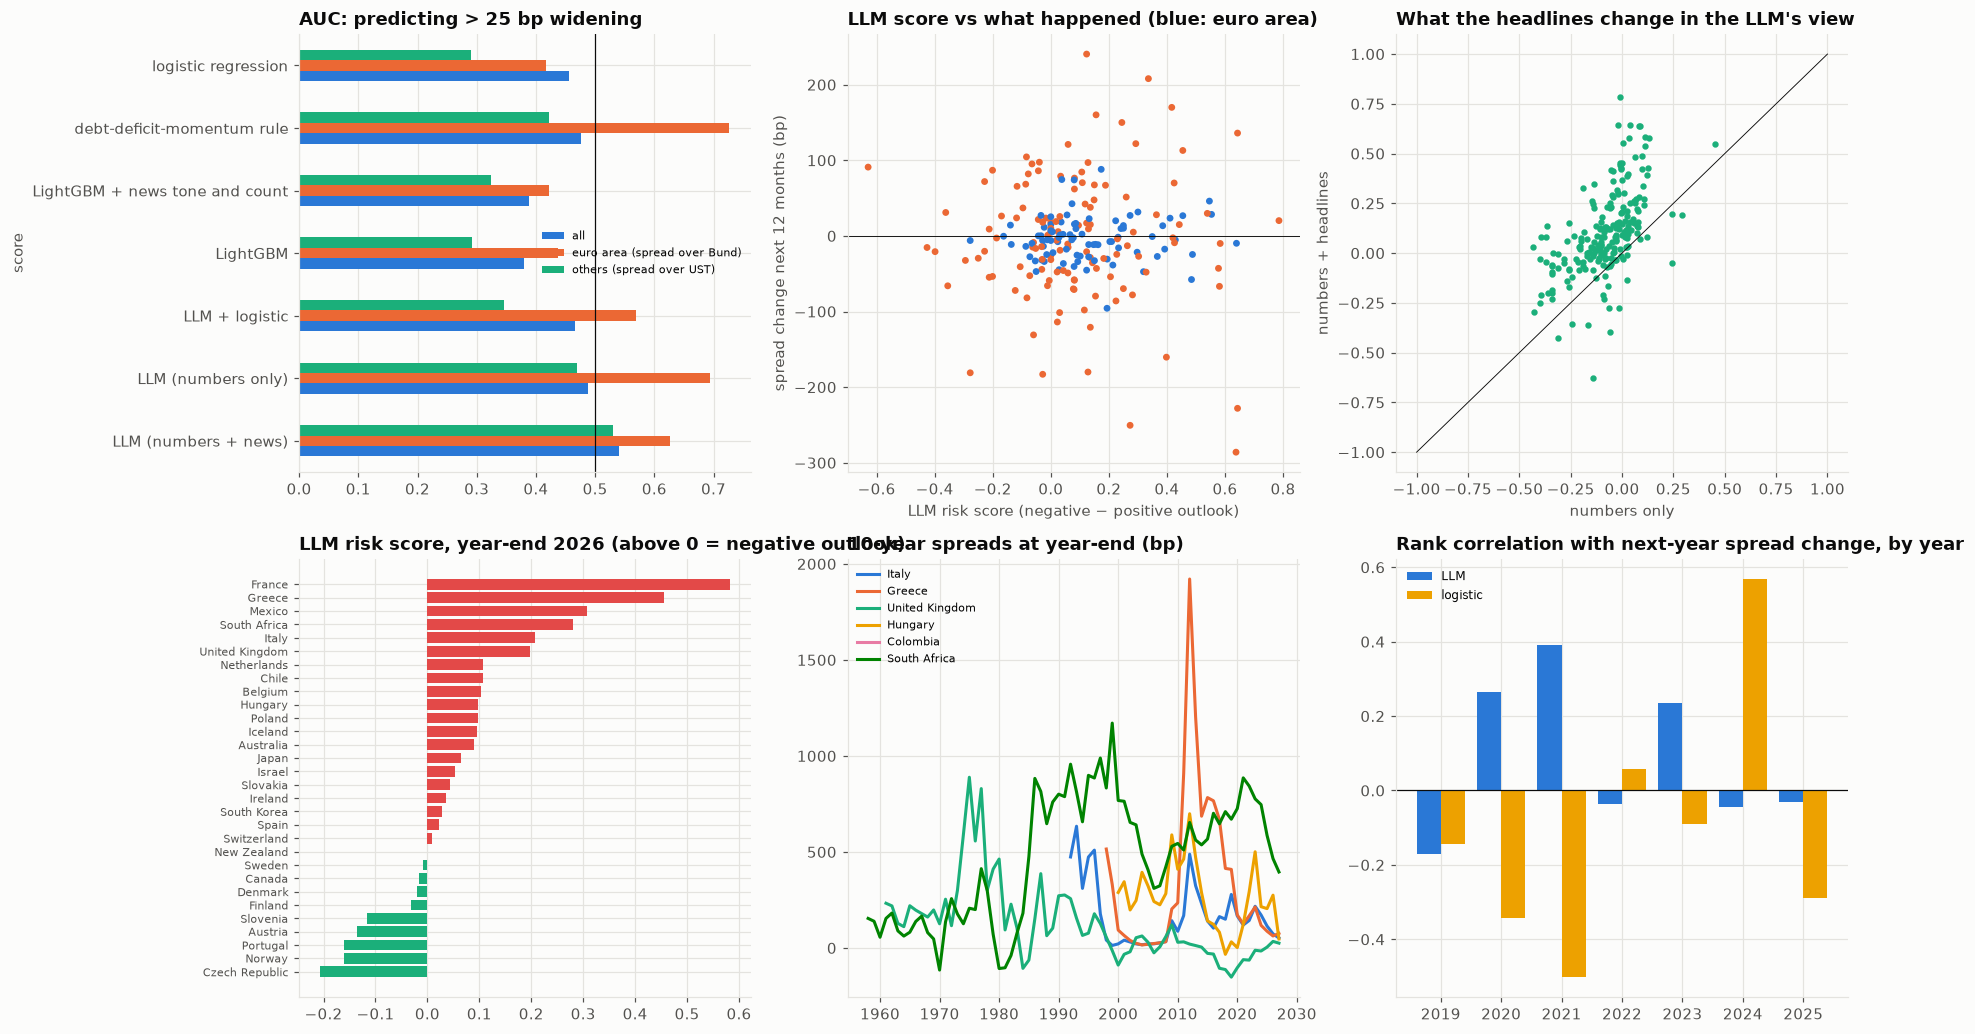

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
p_ = RES.pivot(index="score", columns="sample", values="AUC")
p_.plot.barh(ax=a, color=PALETTE[:3])
a.axvline(0.5, color=INK, lw=0.8)
a.legend(fontsize=7)
a.set_title("AUC: predicting > 25 bp widening")
a = ax[0, 1]
a.scatter(
    EV["llm_score"],
    EV["target_chg"],
    s=12,
    c=np.where(EV["euro"] == 1, PALETTE[0], PALETTE[1]),
)
a.axhline(0, color=INK, lw=0.6)
a.set_xlabel("LLM risk score (negative − positive outlook)")
a.set_ylabel("spread change next 12 months (bp)")
a.set_title("LLM score vs what happened (blue: euro area)")
a = ax[0, 2]
a.scatter(EV["llm_score_no_news"], EV["llm_score"], s=10, color=PALETTE[2])
a.plot([-1, 1], [-1, 1], color=INK, lw=0.6)
a.set_xlabel("numbers only")
a.set_ylabel("numbers + headlines")
a.set_title("What the headlines change in the LLM's view")
a = ax[1, 0]
lt = latest.set_index("country")["llm_score"].sort_values()
a.barh(
    lt.index,
    lt.values,
    color=np.where(lt.values > 0, STATUS["red"], STATUS["green"]),
)
a.tick_params(axis="y", labelsize=7)
a.set_title(
    f"LLM risk score, year-end {PAN['year'].max()} (above 0 = negative"
    " outlook)"
)
a = ax[1, 1]
for c, col in zip(["IT", "GR", "GB", "HU", "CO", "ZA"], PALETTE):
    if c in spread:
        a.plot(spread.index, spread[c], color=col, label=COUNTRIES[c])
a.legend(fontsize=7)
a.set_title("10-year spreads at year-end (bp)")
a = ax[1, 2]
yearly = EV.groupby("year").apply(
    lambda g: spearmanr(g["llm_score"], g["target_chg"])[0],
    include_groups=False,
)
yearly_l = EV.groupby("year").apply(
    lambda g: spearmanr(g["logit"], g["target_chg"])[0], include_groups=False
)
a.bar(
    yearly.index - 0.2, yearly.values, width=0.4, color=PALETTE[0], label="LLM"
)
a.bar(
    yearly_l.index + 0.2,
    yearly_l.values,
    width=0.4,
    color=PALETTE[3],
    label="logistic",
)
a.axhline(0, color=INK, lw=0.8)
a.legend(fontsize=8)
a.set_title("Rank correlation with next-year spread change, by year")
fig.tight_layout()
save_fig(fig, "01_sovereign_llm_outlooks")
plt.show()

In [11]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "AUC by score (all countries)",
        "LLM risk score vs next-year spread change",
        "LLM risk score today",
        "Year-end spreads (bp)",
    ),
)
allr = RES[RES["sample"] == "all"]
dash.add_trace(
    go.Bar(
        x=allr["score"],
        y=allr["AUC"],
        marker_color=PALETTE[0],
        showlegend=False,
    ),
    1,
    1,
)
dash.add_trace(
    go.Scatter(
        x=EV["llm_score"],
        y=EV["target_chg"],
        mode="markers",
        text=EV["country"] + " " + EV["year"].astype(str),
        marker=dict(
            color=np.where(EV["euro"] == 1, PALETTE[0], PALETTE[1]), size=6
        ),
        showlegend=False,
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        x=lt.values,
        y=lt.index,
        orientation="h",
        marker_color=np.where(lt.values > 0, STATUS["red"], STATUS["green"]),
        showlegend=False,
    ),
    2,
    1,
)
for c, col in zip(["IT", "GR", "GB", "HU", "CO", "ZA"], PALETTE):
    if c in spread:
        dash.add_trace(
            go.Scatter(
                x=spread.index,
                y=spread[c],
                name=COUNTRIES[c],
                line=dict(color=col),
            ),
            2,
            2,
        )
dash.update_layout(
    height=900,
    width=1400,
    template="simple_white",
    title="Sovereign credit outlooks with an open LLM",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**The panel.** 30 countries with 10-year yield data (Germany is the euro-area benchmark; Colombia has no yield series on FRED) over year-ends 2017–2026, giving 300 country-years. Of these, 266 have a known outcome; in 26% of them the spread widened by more than 25 bp over the following 12 months. Debt and fiscal balances come from the IMF World Economic Outlook, with the latest year published at each year-end.

**The headlines.** 17,259 Guardian and New York Times search results were found, but 12,490 were dropped because neither their headline nor their standfirst names the country. That leaves 4,769 headlines, a median of 11 per country and year. Coverage is thin for small countries (2–5 a year for Slovenia, Slovakia, Colombia and Chile) and rich for the large ones (20–31 for France, the UK, Japan, Germany and Australia).

**What the LLM says.** Qwen2.5-1.5B labels 284 of 300 country-years "stable", 14 "negative" and 2 "positive". Rating agencies are also mostly "stable", but the model's continuous score (P(negative) − P(positive)) carries more information than the labels.

**Out-of-sample test** (206 country-years, 2019–2025; AUC for "spread widens by more than 25 bp")

| Score | All | Euro area | Others |
| --- | --- | --- | --- |
| LLM, numbers + headlines | **0.54** | 0.63 | **0.53** |
| LLM, numbers only | 0.49 | 0.69 | 0.47 |
| Debt-deficit-momentum rule | 0.48 | **0.73** | 0.42 |
| Logistic regression (walk-forward) | 0.46 | 0.42 | 0.29 |
| LightGBM (walk-forward) | 0.38 | 0.44 | 0.29 |
| LightGBM + news tone and count | 0.39 | 0.42 | 0.32 |

- **Nothing predicts spread changes well across all countries.** The best AUC is 0.54, barely above a coin flip. Spread changes over a year are driven mostly by global rates, risk appetite and surprises that a year-end fact sheet cannot contain.
- **Headlines help the LLM:** they raise its AUC from 0.49 to 0.54 overall, and from 0.47 to 0.53 outside the euro area. The model reads political and fiscal news (elections, protests, budget fights) that the numbers do not show.
- **In the euro area, a simple rule is best.** High debt, a large deficit and a widening spread over the past year score an AUC of 0.73 for widening against the Bund. The LLM reading only the numbers reaches 0.69 and does almost as well, but adding headlines lowers it to 0.63.
- **The trained ML models do worse than chance** (AUC 0.29–0.46). With about 30 observations a year and a target that keeps changing regime (the 2020 shock, the 2022 rate hikes), walk-forward models learn patterns that reverse out of sample. This is a typical low-data trap for sovereign models, and the reason agencies rely on judgment and simple scorecards.

**The outlook notes** for the latest year (`outputs/llm_outlook_notes_latest.csv`) are readable and pick up the right themes: political unrest in France, high debt in Italy and South Africa. They also contain clear errors. Greece is said to hold a "AAA rating"; it is investment grade but well below AAA.

Italy is said to have run a primary surplus "since 2019". **A small LLM can draft and sort, but every figure and claim in a sovereign note must be checked against the fact sheet.**

**Limitations**
- Market spreads, not agency ratings, are the target.
- The panel is small (about 30 countries × 7 test years), so the AUC intervals are wide.
- Fiscal data are latest vintages, not real-time, so a little future revision information leaks in.
- Headlines from two English-language newspapers only.
- A 1.5B-parameter model with no fine-tuning.

In [12]:
PAN.drop(columns=["headlines"]).to_csv(
    OUT_DIR / "country_year_panel_and_scores.csv", index=False
)
RES.to_csv(OUT_DIR / "outlook_accuracy.csv", index=False)
NOTES.to_csv(OUT_DIR / "llm_outlook_notes_latest.csv", index=False)
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_sovereign_llm_outlooks.png, country_year_panel_and_scores.csv, dashboard.html, dashboard.png, llm_outlook_notes_latest.csv, outlook_accuracy.csv


## References

### Finance and regulation

- Cantor, R., & Packer, F. (1996). Determinants and impact of sovereign credit ratings. *Economic Policy Review, 2*(2), 37–53. https://doi.org/10.2139/ssrn.1028774
- Reinhart, C. M., & Rogoff, K. S. (2009). *This time is different: Eight centuries of financial folly*. Princeton University Press. https://doi.org/10.1515/9781400831722
- Afonso, A., Gomes, P., & Rother, P. (2011). Short- and long-run determinants of sovereign debt credit ratings. *International Journal of Finance & Economics, 16*(1), 1–15. https://doi.org/10.1002/ijfe.416
- Longstaff, F. A., Pan, J., Pedersen, L. H., & Singleton, K. J. (2011). How sovereign is sovereign credit risk? *American Economic Journal: Macroeconomics, 3*(2), 75–103. https://doi.org/10.1257/mac.3.2.75
- Baker, S. R., Bloom, N., & Davis, S. J. (2016). Measuring economic policy uncertainty. *The Quarterly Journal of Economics, 131*(4), 1593–1636. https://doi.org/10.1093/qje/qjw024

### Machine learning and deep learning

- Qwen Team. (2024). Qwen2.5 technical report. *arXiv*. https://arxiv.org/abs/2412.15115
- Brown, T., Mann, B., Ryder, N., Subbiah, M., Kaplan, J., Dhariwal, P., … Amodei, D. (2020). Language models are few-shot learners. *Advances in Neural Information Processing Systems, 33*. https://arxiv.org/abs/2005.14165
- Wu, S., Irsoy, O., Lu, S., Dabravolski, V., Dredze, M., Gehrmann, S., … Mann, G. (2023). BloombergGPT: A large language model for finance. *arXiv*. https://arxiv.org/abs/2303.17564
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html